# Proyecto 01: Retail Intelligence
## A2: Análisis de Rentabilidad y Comportamiento de Compra
**Asignatura:** Tópicos Especiales para la Gestión de Datos  
**Caso:** RetailVenture C.A.  
**Autor:** Daniel Azuaje (Equipo RetailVenture)

---

### Objetivos de la Actividad:
1. **A2.1 Contribución al Margen Bruto:** Identificar segmentos, categorías y canales con mayor/menor aporte al margen total.
2. **A2.2 Customer Lifetime Value (CLV):** Estimar el CLV por segmento e identificar segmentos en declive.
3. **A2.3 Estacionalidad:** Analizar picos, valles y tendencias temporales por categoría y canal (2023 vs 2024).
4. **A2.4 Efecto de Descuentos:** Evaluar si el volumen compensa la pérdida de margen y detectar ventas bajo costo.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual ejecutivo
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Fuente de datos: lectura local de clean (o conexión a Supabase)
DATA_PATH = Path("../data/clean")

df_trx = pd.read_csv(DATA_PATH / "transacciones_maestra.csv", parse_dates=["fecha"])
df_cli = pd.read_csv(DATA_PATH / "clientes_maestra.csv")
df_prd = pd.read_csv(DATA_PATH / "productos_limpio.csv")

print(f"Transacciones cargadas: {len(df_trx):,}")
print(f"Ingreso neto total:  ${df_trx['monto_neto'].sum():,.2f}")
print(f"Margen bruto total:  ${df_trx['margen_bruto'].sum():,.2f} ({100*df_trx['margen_bruto'].sum()/df_trx['monto_neto'].sum():.2f}% del ingreso)")


Transacciones cargadas: 50,000
Ingreso neto total:  $17,392,987.48
Margen bruto total:  $4,310,329.05 (24.78% del ingreso)


---
## A2.1 Contribución al Margen Bruto

Analizamos la rentabilidad multidimensional:
- **Por Categoría de Producto**
- **Por Canal de Venta**
- **Por Segmento de Cliente**
- **Cruce Causal:** Canal × Categoría (¿Dónde se destruye margen?)


In [2]:
# Función para resumen de contribución
TOTAL_INGRESO = df_trx['monto_neto'].sum()
TOTAL_MARGEN = df_trx['margen_bruto'].sum()

def tabla_contribucion(df, dimension):
    res = df.groupby(dimension).agg(
        transacciones=('transaccion_id', 'count'),
        ingreso_neto=('monto_neto', 'sum'),
        margen_bruto=('margen_bruto', 'sum'),
        margen_neto_devol=('margen_neto_devol', 'sum'),
        tasa_devolucion=('devuelto', 'mean'),
        descuento_promedio=('descuento', 'mean')
    ).reset_index()
    
    res['pct_ingreso'] = (100 * res['ingreso_neto'] / TOTAL_INGRESO).round(2)
    res['pct_margen'] = (100 * res['margen_bruto'] / TOTAL_MARGEN).round(2)
    res['margen_pct_real'] = (100 * res['margen_bruto'] / res['ingreso_neto']).round(2)
    res['tasa_devolucion'] = (100 * res['tasa_devolucion']).round(2)
    res['descuento_promedio'] = (100 * res['descuento_promedio']).round(2)
    
    return res.sort_values(by='margen_bruto', ascending=False)


### 1. Rentabilidad por Categoría de Producto

In [3]:
cat_summary = tabla_contribucion(df_trx, 'categoria')
cat_summary[['categoria', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'tasa_devolucion']]


,categoria,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,tasa_devolucion
4,Hogar_y_Deco,4465864.98,25.68,1353038.11,31.39,30.30,9.79
3,Electrónica,7662506.08,44.06,1049301.24,24.34,13.69,17.65
2,Deportes,2592709.06,14.91,907213.71,21.05,34.99,10.67
5,Ropa_y_Calzado,1513396.68,8.70,597005.29,13.85,39.45,21.78
1,Belleza_y_Salud,748631.63,4.30,309502.60,7.18,41.34,10.59
0,Alimentos_y_Bebidas,409879.05,2.36,94268.10,2.19,23.00,10.16


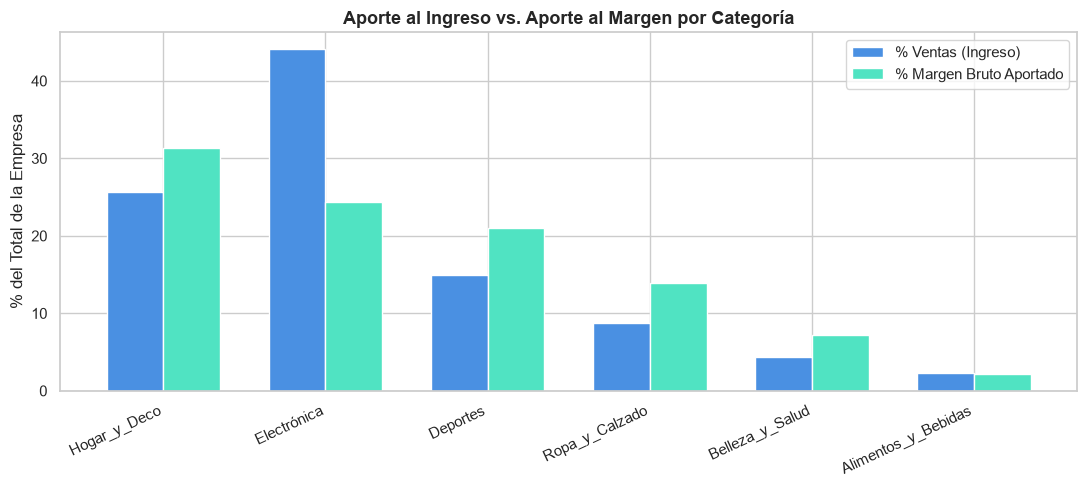

In [4]:
fig, ax1 = plt.subplots(figsize=(11, 5))

# Gráfico dual: Volumen de Ingreso vs Margen Bruto
x = np.arange(len(cat_summary))
width = 0.35

rects1 = ax1.bar(x - width/2, cat_summary['pct_ingreso'], width, label='% Ventas (Ingreso)', color='#4A90E2')
rects2 = ax1.bar(x + width/2, cat_summary['pct_margen'], width, label='% Margen Bruto Aportado', color='#50E3C2')

ax1.set_ylabel('% del Total de la Empresa')
ax1.set_title('Aporte al Ingreso vs. Aporte al Margen por Categoría', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(cat_summary['categoria'], rotation=25, ha='right')
ax1.legend()
plt.tight_layout()
plt.show()


### 2. Rentabilidad por Canal de Venta

In [5]:
canal_summary = tabla_contribucion(df_trx, 'canal')
canal_summary[['canal', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'descuento_promedio']]


,canal,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,descuento_promedio
2,tienda_fisica,7862504.26,45.21,2046091.64,47.47,26.02,3.73
1,online,6547309.24,37.64,1491185.50,34.60,22.78,7.55
0,app_movil,2983173.98,17.15,773051.91,17.93,25.91,3.69


C:\Users\danie\AppData\Local\Temp\ipykernel_7424\3586025587.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=canal_summary, x='canal', y='margen_pct_real', palette='Blues_d')


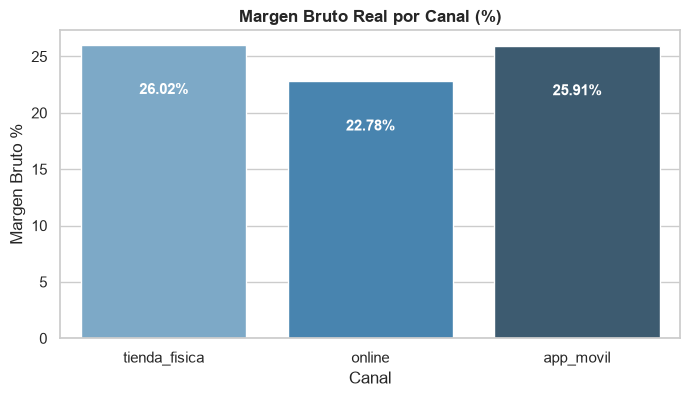

In [6]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=canal_summary, x='canal', y='margen_pct_real', palette='Blues_d')
plt.title('Margen Bruto Real por Canal (%)', fontsize=12, fontweight='bold')
plt.ylabel('Margen Bruto %')
plt.xlabel('Canal')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 4),
                ha='center', va='center', color='white', fontweight='bold')
plt.show()


### 3. Rentabilidad por Segmento de Clientes (Pareto)

In [7]:
seg_summary = tabla_contribucion(df_trx, 'segmento')
seg_summary[['segmento', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real']]


,segmento,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real
1,Frecuente,8766759.08,50.40,2131971.05,49.46,24.32
4,Premium,5280660.84,30.36,1345562.64,31.22,25.48
0,Esporádico,2701501.87,15.53,674499.16,15.65,24.97
3,Nuevo,326779.06,1.88,80590.18,1.87,24.66
2,Inactivo,317286.63,1.82,77706.02,1.80,24.49


### 4. Cruce Causal: Descuento Online vs. Destrucción de Margen

In [8]:
cruce_desc = df_trx.pivot_table(index='categoria', columns='canal', values='descuento', aggfunc=lambda s: (s.mean()*100).round(2))
cruce_margen = df_trx.pivot_table(index='categoria', columns='canal', values='margen_pct_real', aggfunc='mean').round(2)

print("--- Descuento Promedio (%) por Categoría y Canal ---")
display(cruce_desc)

print("\n--- Margen Real (%) por Categoría y Canal ---")
display(cruce_margen)


--- Descuento Promedio (%) por Categoría y Canal ---


canal,app_movil,online,tienda_fisica
categoria,,,
Alimentos_y_Bebidas,3.83,7.38,3.71
Belleza_y_Salud,3.71,7.40,3.77
Deportes,3.96,7.89,3.69
Electrónica,3.78,7.62,3.80
Hogar_y_Deco,3.59,7.45,3.68
Ropa_y_Calzado,3.28,7.53,3.73



--- Margen Real (%) por Categoría y Canal ---


canal,app_movil,online,tienda_fisica
categoria,,,
Alimentos_y_Bebidas,24.38,21.21,24.37
Belleza_y_Salud,41.80,39.52,41.89
Deportes,36.02,33.05,35.75
Electrónica,14.94,11.38,15.01
Hogar_y_Deco,31.75,28.61,31.66
Ropa_y_Calzado,40.72,38.12,40.53


### 5. Drill-down por Subcategoría: Ganadoras vs. Destructoras de Margen

Dentro de cada categoría, no todos los productos aportan igual. Identificamos:
- **Top 5 Subcategorías Ganadoras:** Mayor masa de margen bruto aportada a la empresa.
- **Bottom 5 Subcategorías Menos Rentables:** Productos con baja rotación o margen comprimido.


In [9]:
sub_summary = df_trx.groupby(['categoria', 'subcategoria']).agg(
    ingreso_neto=('monto_neto', 'sum'),
    margen_bruto=('margen_bruto', 'sum'),
    margen_pct_real=('margen_pct_real', 'mean'),
    tasa_devolucion=('devuelto', 'mean')
).reset_index()

sub_summary['pct_margen_total'] = (100 * sub_summary['margen_bruto'] / TOTAL_MARGEN).round(2)
sub_summary['tasa_devolucion'] = (100 * sub_summary['tasa_devolucion']).round(2)
sub_summary = sub_summary.sort_values(by='margen_bruto', ascending=False)

top5 = sub_summary.head(5)
bottom5 = sub_summary.tail(5)

print("=== TOP 5 SUBCATEGORÍAS GANADORAS ===")
display(top5[['categoria', 'subcategoria', 'margen_bruto', 'pct_margen_total', 'margen_pct_real', 'tasa_devolucion']])

print("\n=== BOTTOM 5 SUBCATEGORÍAS MENOS RENTABLES ===")
display(bottom5[['categoria', 'subcategoria', 'margen_bruto', 'pct_margen_total', 'margen_pct_real', 'tasa_devolucion']])


=== TOP 5 SUBCATEGORÍAS GANADORAS ===


,categoria,subcategoria,margen_bruto,pct_margen_total,margen_pct_real,tasa_devolucion
16,Hogar_y_Deco,Baño,454511.79,10.54,31.509555,10.26
18,Hogar_y_Deco,Decoración,430806.04,9.99,29.316373,8.83
14,Electrónica,Computadoras,387587.50,8.99,12.944728,17.64
19,Hogar_y_Deco,Muebles,302639.77,7.02,30.358262,10.68
8,Deportes,Calzado_deportivo,281216.33,6.52,34.133424,11.30



=== BOTTOM 5 SUBCATEGORÍAS MENOS RENTABLES ===


,categoria,subcategoria,margen_bruto,pct_margen_total,margen_pct_real,tasa_devolucion
6,Belleza_y_Salud,Skincare,51568.92,1.20,40.461269,9.35
0,Alimentos_y_Bebidas,Bebidas,27284.56,0.63,21.392708,10.00
1,Alimentos_y_Bebidas,Congelados,26626.37,0.62,25.527267,10.38
2,Alimentos_y_Bebidas,Orgánicos,20644.25,0.48,22.341426,9.23
3,Alimentos_y_Bebidas,Snacks,19712.92,0.46,23.194317,11.12


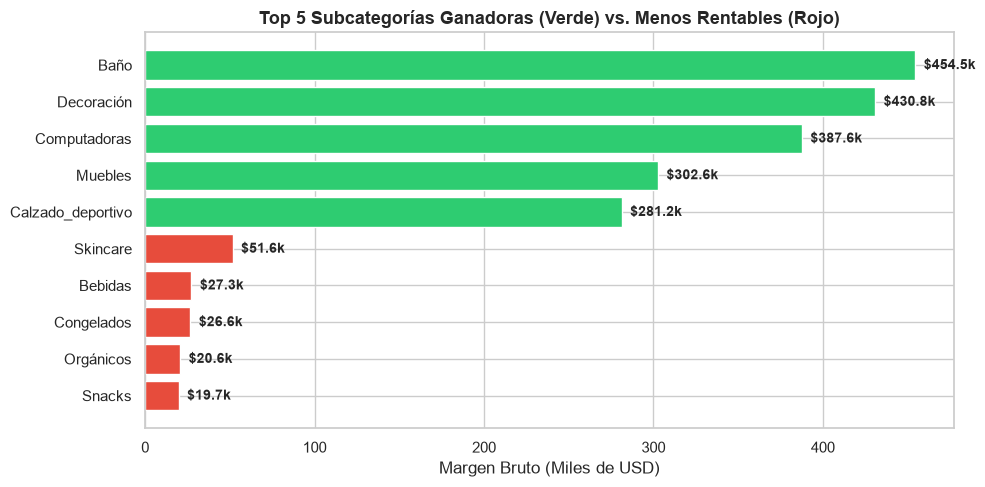

In [10]:
# Gráfico comparativo Top 5 vs Bottom 5
fig, ax = plt.subplots(figsize=(10, 5))

top_bottom = pd.concat([top5, bottom5]).sort_values(by='margen_bruto', ascending=True)
colors = ['#E74C3C' if x in bottom5['subcategoria'].values else '#2ECC71' for x in top_bottom['subcategoria']]

ax.barh(top_bottom['subcategoria'], top_bottom['margen_bruto'] / 1000, color=colors)
ax.set_xlabel('Margen Bruto (Miles de USD)')
ax.set_title('Top 5 Subcategorías Ganadoras (Verde) vs. Menos Rentables (Rojo)', fontsize=13, fontweight='bold')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"${width:,.1f}k", (width + 5, p.get_y() + p.get_height()/2.),
                va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### 6. Rentabilidad Territorial: Margen por Ciudad

Analizamos la concentración geográfica de la rentabilidad:
- ¿El margen varía por plaza o es uniforme?
- ¿Dónde se concentra el riesgo operativo de la empresa?


In [11]:
ciu_summary = tabla_contribucion(df_trx, 'ciudad')
display(ciu_summary[['ciudad', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'descuento_promedio']])


,ciudad,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,descuento_promedio
1,Caracas,6809521.88,39.15,1683145.89,39.05,24.72,5.24
2,Maracaibo,3198033.09,18.39,796420.53,18.48,24.90,5.07
7,Valencia,2629965.46,15.12,652653.86,15.14,24.82,5.09
0,Barquisimeto,1836284.41,10.56,437866.42,10.16,23.85,5.29
5,Puerto La Cruz,885757.15,5.09,227357.97,5.27,25.67,5.15
4,Mérida,863604.51,4.97,220968.21,5.13,25.59,5.38
3,Maturín,715644.68,4.11,176465.27,4.09,24.66,5.17
6,San Cristóbal,454176.30,2.61,115450.90,2.68,25.42,5.18


C:\Users\danie\AppData\Local\Temp\ipykernel_7424\2844665690.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=ciu_summary, x='ciudad', y='pct_margen', palette='Greens_r')


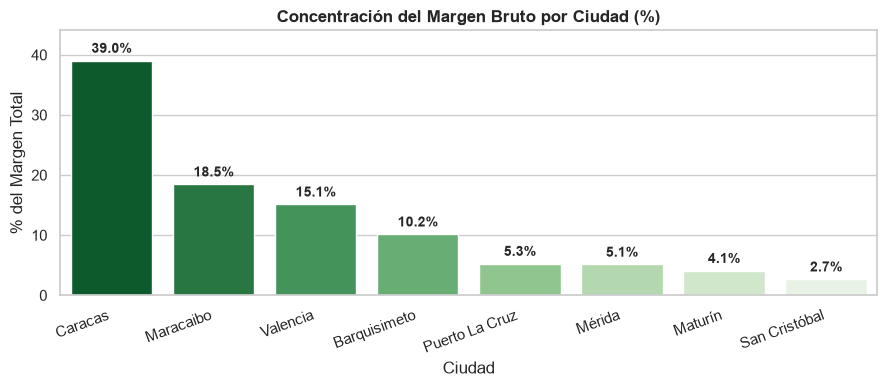

In [12]:
plt.figure(figsize=(9, 4))
ax = sns.barplot(data=ciu_summary, x='ciudad', y='pct_margen', palette='Greens_r')
plt.title('Concentración del Margen Bruto por Ciudad (%)', fontsize=12, fontweight='bold')
plt.ylabel('% del Margen Total')
plt.xlabel('Ciudad')
plt.xticks(rotation=20, ha='right')

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.8),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, ciu_summary['pct_margen'].max() + 5)
plt.tight_layout()
plt.show()


### 7. Concentración de Clientes: Curva de Pareto (80/20)

Evaluamos el principio de Pareto a nivel individual de cliente:
- ¿Qué porcentaje de los clientes explica el 80% del margen bruto de la empresa?
- Respaldo cuantitativo para priorizar la retención de clientes clave (conecta directo con A3 - Churn).


In [13]:
cli_margen = df_trx.groupby('cliente_id')['margen_bruto'].sum().sort_values(ascending=False).reset_index()
cli_margen['margen_acumulado'] = cli_margen['margen_bruto'].cumsum()
cli_margen['pct_margen_acum'] = 100 * cli_margen['margen_acumulado'] / TOTAL_MARGEN
cli_margen['pct_clientes'] = 100 * (cli_margen.index + 1) / len(cli_margen)

# Puntos clave
p20_val = cli_margen[cli_margen['pct_clientes'] <= 20]['pct_margen_acum'].iloc[-1]
p80_idx = (cli_margen['pct_margen_acum'] >= 80).idxmax()
p80_cli_pct = cli_margen.loc[p80_idx, 'pct_clientes']

print(f"Hallazgo Pareto:")
print(f"• El 20% de los clientes genera el {p20_val:.1f}% del margen bruto total.")
print(f"• El 80% del margen total es generado por solo el {p80_cli_pct:.1f}% de la base de clientes.")


Hallazgo Pareto:
• El 20% de los clientes genera el 56.0% del margen bruto total.
• El 80% del margen total es generado por solo el 38.0% de la base de clientes.


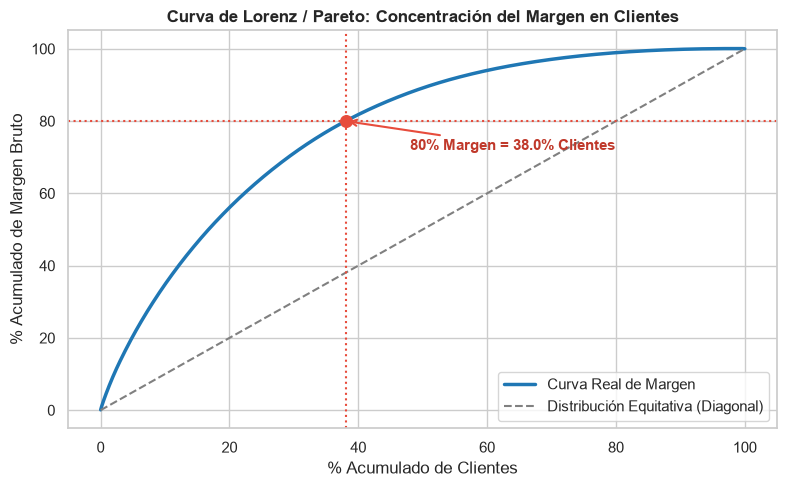

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(cli_margen['pct_clientes'], cli_margen['pct_margen_acum'], color='#1F77B4', lw=2.5, label='Curva Real de Margen')
plt.plot([0, 100], [0, 100], color='gray', linestyle='--', label='Distribución Equitativa (Diagonal)')

# Marcar punto 80% del margen
plt.axhline(80, color='#E74C3C', linestyle=':', lw=1.5)
plt.axvline(p80_cli_pct, color='#E74C3C', linestyle=':', lw=1.5)
plt.scatter([p80_cli_pct], [80], color='#E74C3C', s=70, zorder=5)

plt.annotate(f"80% Margen = {p80_cli_pct:.1f}% Clientes",
             xy=(p80_cli_pct, 80), xytext=(p80_cli_pct + 10, 72),
             arrowprops=dict(arrowstyle="->", color='#E74C3C', lw=1.5),
             fontweight='bold', color='#C0392B')

plt.title('Curva de Lorenz / Pareto: Concentración del Margen en Clientes', fontsize=12, fontweight='bold')
plt.xlabel('% Acumulado de Clientes')
plt.ylabel('% Acumulado de Margen Bruto')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


---
## A2.2 Customer Lifetime Value (CLV) por Segmento
*(Próximo paso: calibrar con la tasa de churn del equipo)*


In [15]:
# Esqueleto preliminar de CLV
# CLV = Margen promedio por compra x Compras anuales x Vida esperada (1 / churn)
# En desarrollo...


---
## A2.3 Análisis de Estacionalidad de Ventas (2023 vs 2024)
*(Próximo paso: descomposición mensual y picos/valles)*


In [16]:
# En desarrollo...


---
## A2.4 Elasticidad y Efecto de Descuentos
*(Próximo paso: análisis de punto de equilibrio y ventas bajo costo)*


In [17]:
# En desarrollo...
